## Setup

## Install OCR and layout dependencies

In [1]:
!apt-get update -qq && apt-get install -y -qq tesseract-ocr > /dev/null
!pip install -q ultralytics pytesseract jiwer easyocr

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## Verify installed OCR tools

In [2]:
!tesseract --version
!pip list 2>/dev/null | grep -i -E "ultralytics|pytesseract|jiwer"

tesseract 5.3.4
 leptonica-1.82.0
  libgif 5.2.1 : libjpeg 8d (libjpeg-turbo 2.1.5) : libpng 1.6.43 : libtiff 4.5.1 : zlib 1.3 : libwebp 1.3.2 : libopenjp2 2.5.0
 Found AVX512BW
 Found AVX512F
 Found AVX2
 Found AVX
 Found FMA
 Found SSE4.1
 Found OpenMP 201511
 Found libarchive 3.7.2 zlib/1.3 liblzma/5.4.5 bz2lib/1.0.8 liblz4/1.9.4 libzstd/1.5.5
 Found libcurl/8.5.0 OpenSSL/3.0.13 zlib/1.3 brotli/1.1.0 zstd/1.5.5 libidn2/2.3.7 libpsl/0.21.2 (+libidn2/2.3.7) libssh/0.10.6/openssl/zlib nghttp2/1.59.0 librtmp/2.3 OpenLDAP/2.6.10
jiwer                                 4.0.0
pytesseract                           0.3.13
ultralytics                           8.4.201
ultralytics-platform                  0.1.102
ultralytics-thop                      2.2.4


## Detect, crop and OCR one page

## Detect page regions and OCR text

In [3]:
import json, random, cv2, torch, pytesseract
from pathlib import Path
from ultralytics import YOLO

WEIGHTS = "/kaggle/input/datasets/mohamedahmed29/doclaynet-yolov8s-baseline/doclaynet_yolov8s_baseline.pt"   
ROOT = Path("/kaggle/input/datasets/dlaproj123/doclaynet")
NAMES = ["Caption", "Footnote", "Formula", "List-item", "Page-footer", "Page-header",
         "Picture", "Section-header", "Table", "Text", "Title"]
TEXT_CLASSES = {"Text", "Title", "Section-header", "List-item", "Caption",
                "Footnote", "Page-header", "Page-footer"}

model = YOLO(WEIGHTS)
device = 0 if torch.cuda.is_available() else "cpu"

# pick a page from the val split, so the model hasn't trained on it
val_pages = json.load(open(ROOT / "COCO" / "val.json"))["images"]
fn = random.choice(val_pages)["file_name"]
img = cv2.imread(str(ROOT / "PNG" / fn))

res = model.predict(img, imgsz=640, conf=0.25, device=device, verbose=False)[0]

# rough reading order: top to bottom, then left to right
boxes = sorted(res.boxes, key=lambda b: (float(b.xyxy[0][1]), float(b.xyxy[0][0])))
for b in boxes:
    label = NAMES[int(b.cls)]
    if label not in TEXT_CLASSES:
        continue
    x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
    crop = cv2.resize(img[y1:y2, x1:x2], None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    text = pytesseract.image_to_string(crop, config="--psm 6").strip()
    print(f"[{label}] {text}\n")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
[Page-header] Title here

[Page-header] TECHNIGAR REPORT

[Section-header] Abbreviations

[Text] Abbreviations

[Text] Dummy
Please don’t kill the section break below!

[Text] mutttetetateted
Please don’t kill the section break below!

[Page-footer] iv



## Visualize detections and extracted text

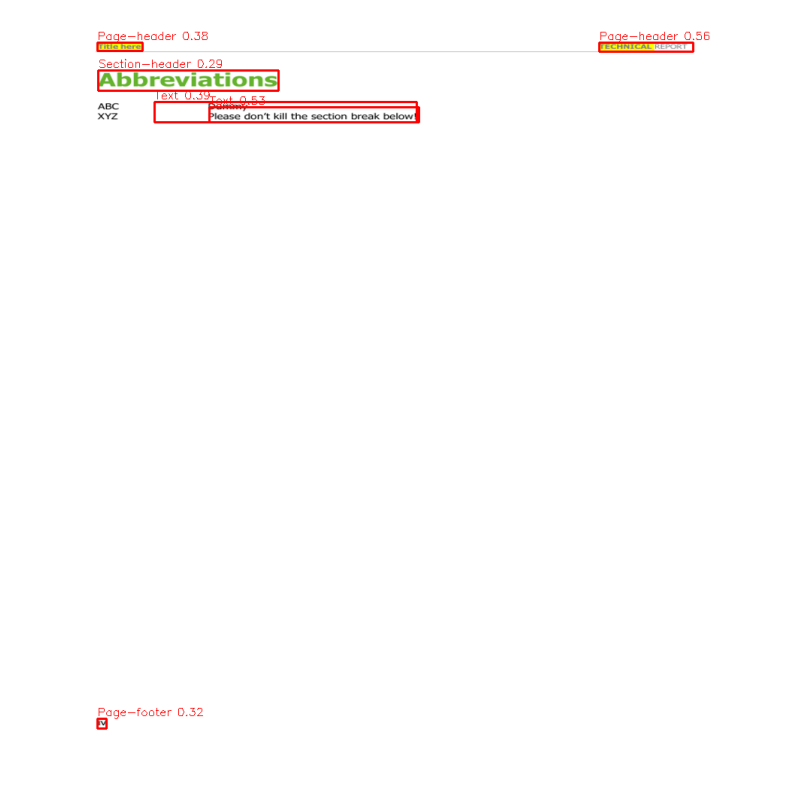

[Page-header] Title here

[Page-header] TECHNIGAR REPORT

[Section-header] Abbreviations

[Text] Dummy
Please don’t kill the section break below!

[Text] mutttetetateted
Please don’t kill the section break below!

[Page-footer] iv



[('Page-header', 'Title here'),
 ('Page-header', 'TECHNIGAR REPORT'),
 ('Section-header', 'Abbreviations'),
 ('Text', 'Dummy\nPlease don’t kill the section break below!'),
 ('Text', 'mutttetetateted\nPlease don’t kill the section break below!'),
 ('Page-footer', 'iv')]

In [4]:
import matplotlib.pyplot as plt

def run_page(fn, conf=0.25, show=True):
    img = cv2.imread(str(ROOT / "PNG" / fn))
    res = model.predict(img, imgsz=640, conf=conf, device=device,
                        agnostic_nms=True, verbose=False)[0]
    boxes = sorted(res.boxes, key=lambda b: (float(b.xyxy[0][1]), float(b.xyxy[0][0])))
    vis, out = img.copy(), []
    for b in boxes:
        label = NAMES[int(b.cls)]
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(vis, f"{label} {float(b.conf):.2f}", (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
        if label in TEXT_CLASSES:
            crop = cv2.resize(img[y1:y2, x1:x2], None, fx=2, fy=2,
                              interpolation=cv2.INTER_CUBIC)
            out.append((label, pytesseract.image_to_string(crop, config="--psm 6").strip()))
    if show:
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
        for label, text in out:
            print(f"[{label}] {text}\n")
    return out

run_page(fn)

## Export crops (small, short text, 12 total)

## Select and export 12 OCR evaluation crops

In [17]:
import shutil, random
from pathlib import Path

EVAL = Path('/kaggle/working/ocr_eval')
EVAL.mkdir(parents=True, exist_ok=True)

shutil.rmtree(EVAL / "crops", ignore_errors=True)   # remove the old crops
(EVAL / "crops").mkdir(parents=True)

random.seed(0)
MAX_W, MAX_H = 220, 45     # small crop = short text (pixels on the original page)
PER_CLASS = 3              # at most 3 crops per class, so one class doesn't dominate
N_TOTAL = 12

cands = []
for p in random.sample(val_pages, 30):
    img = cv2.imread(str(ROOT / "PNG" / p["file_name"]))
    res = model.predict(img, imgsz=640, conf=0.25, device=device,
                        agnostic_nms=True, verbose=False)[0]
    for j, b in enumerate(res.boxes):
        label = NAMES[int(b.cls)]
        if label not in TEXT_CLASSES:
            continue
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        crop = img[y1:y2, x1:x2]
        h, w = crop.shape[:2]
        if h < 8 or w < 25 or h > MAX_H or w > MAX_W:
            continue
        cands.append({"id": f"{Path(p['file_name']).stem[:6]}_{j}", "label": label, "crop": crop})

random.shuffle(cands)
count, rows = {}, []
for c in cands:
    if count.get(c["label"], 0) >= PER_CLASS:
        continue
    count[c["label"]] = count.get(c["label"], 0) + 1
    cv2.imwrite(str(EVAL / "crops" / f"{c['id']}.png"), c["crop"])
    rows.append({"id": c["id"], "label": c["label"]})
    if len(rows) == N_TOTAL:
        break

print(len(cands), "small candidates ->", len(rows), "selected:", count)

81 small candidates -> 12 selected: {'Text': 3, 'Page-header': 3, 'Section-header': 3, 'List-item': 2, 'Page-footer': 1}


## Show Crops

## Render and inspect the selected text crops

rows: 12 | files on disk: 12


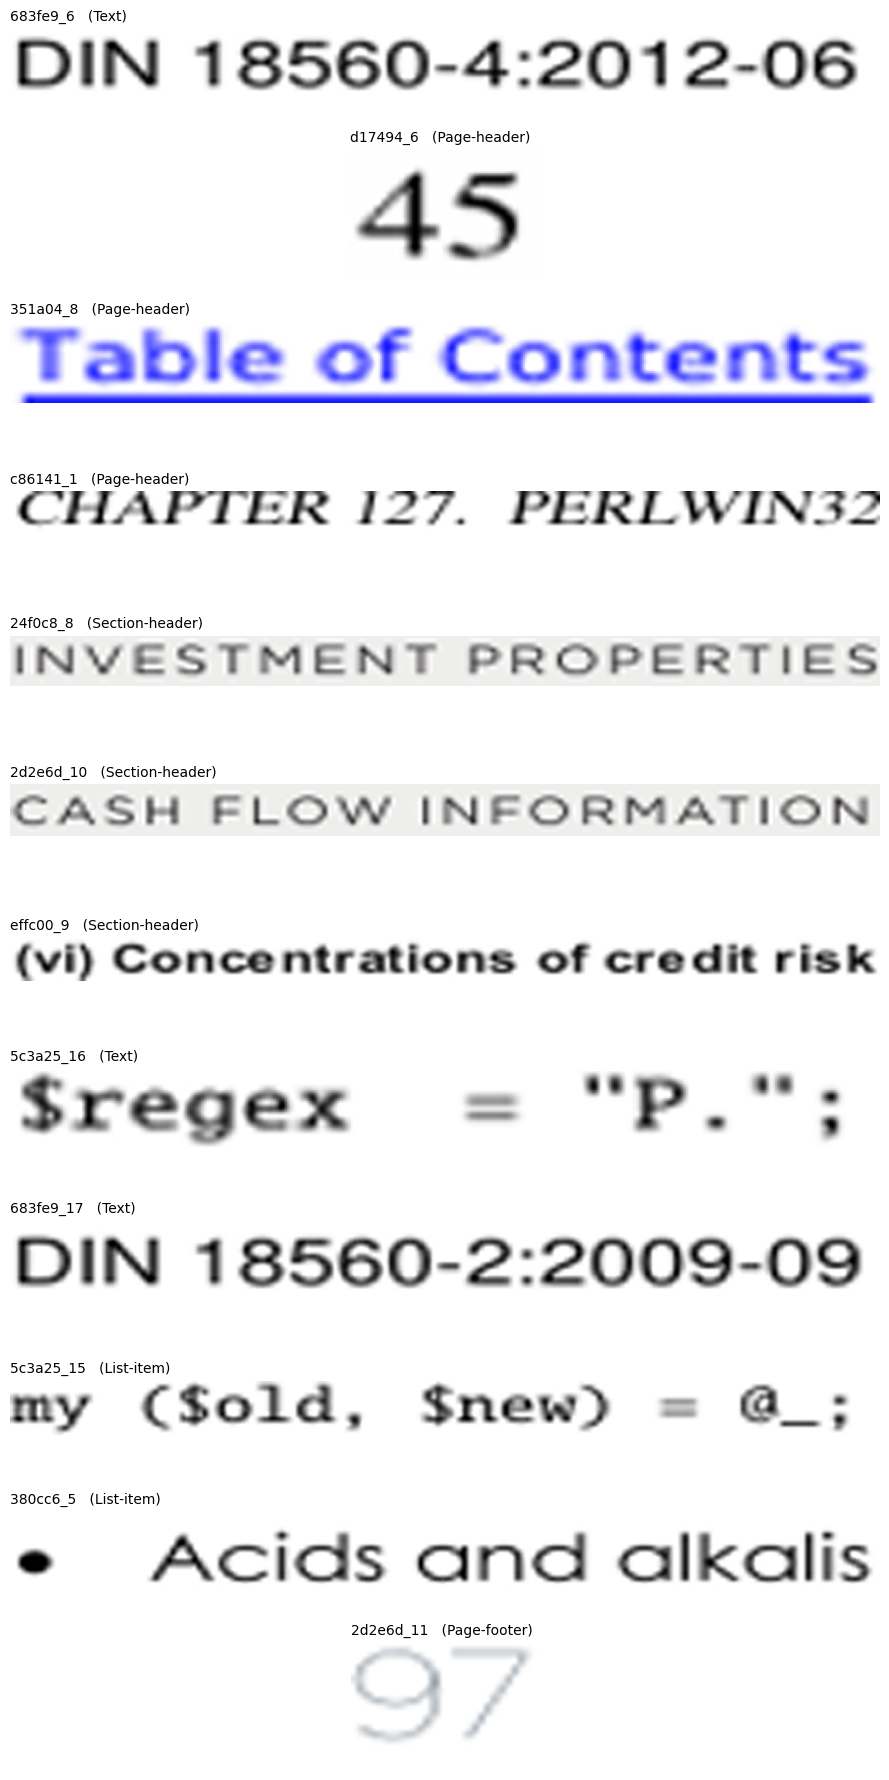

In [20]:
import matplotlib.pyplot as plt

files = sorted((EVAL / "crops").glob("*.png"))
print("rows:", len(rows), "| files on disk:", len(files))

fig, axes = plt.subplots(len(rows), 1, figsize=(9, 1.5 * len(rows)))
axes = [axes] if len(rows) == 1 else axes
for ax, r in zip(axes, rows):
    img = cv2.imread(str(EVAL / "crops" / f"{r['id']}.png"))
    img = cv2.resize(img, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)   # enlarge so it's readable
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['id']}   ({r['label']})", fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Generate a ground-truth entry template

In [18]:
print("truth = {")
for r in rows:
    print(f'    "{r["id"]}": "",')
print("}")

truth = {
    "683fe9_6": "",
    "d17494_6": "",
    "351a04_8": "",
    "c86141_1": "",
    "24f0c8_8": "",
    "2d2e6d_10": "",
    "effc00_9": "",
    "5c3a25_16": "",
    "683fe9_17": "",
    "5c3a25_15": "",
    "380cc6_5": "",
    "2d2e6d_11": "",
}


## Enter the reference transcription for each crop

In [26]:
truth  = {
    "683fe9_6": "DIN 18560-4:2012-06",
    "d17494_6": "45",
    "351a04_8": "Table of Contents",
    "c86141_1": "CHAPTER 127. PERLWIN32",
    "24f0c8_8": "INVESTMENT PROPERTIES",
    "2d2e6d_10": "CASH FLOW INFORMATION",
    "effc00_9": "(vi) Concentrations of credit risk",
    "5c3a25_16": '$regex = "p.";',
    "683fe9_17": "DIN 18560-2:2009-09",
    "5c3a25_15": "my ($old, $new) = @_;",
    "380cc6_5": ". Acids and alkalis",
    "2d2e6d_11": "97",
}

## Evaluate Tesseract preprocessing settings

In [27]:
import jiwer, re
import pandas as pd

def norm(s):
    return re.sub(r"\s+", " ", s).strip()

def prep_img(img, scale, prep, border):
    if scale != 1:
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    if prep in ("gray", "otsu"):
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if prep == "otsu":
        _, img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if border:
        value = 255 if img.ndim == 2 else (255, 255, 255)
        img = cv2.copyMakeBorder(img, border, border, border, border,
                                 cv2.BORDER_CONSTANT, value=value)
    return img

def ocr(img, scale=2, psm=6, prep="color", border=0):
    return pytesseract.image_to_string(prep_img(img, scale, prep, border),
                                       config=f"--psm {psm}").strip()

labeled = [r for r in rows if truth.get(r["id"], "").strip()
           and truth[r["id"]].strip().upper() != "SKIP"]
crops = {r["id"]: cv2.imread(str(EVAL / "crops" / f"{r['id']}.png")) for r in labeled}
refs = [norm(truth[r["id"]]) for r in labeled]

def score(**cfg):
    hyps = [norm(ocr(crops[r["id"]], **cfg)) for r in labeled]
    return jiwer.cer(refs, hyps), jiwer.wer(refs, hyps), hyps

base = dict(scale=2, psm=6, prep="color", border=0)
configs = {
    "baseline (2x, psm 6)": base,
    "1x":        {**base, "scale": 1},
    "3x":        {**base, "scale": 3},
    "psm 7":     {**base, "psm": 7},
    "gray":      {**base, "prep": "gray"},
    "otsu":      {**base, "prep": "otsu"},
    "border 10": {**base, "border": 10},
}

results, hyps_by_cfg = [], {}
for name, cfg in configs.items():
    cer, wer, hyps = score(**cfg)
    hyps_by_cfg[name] = hyps
    results.append({"config": name, "CER": round(cer, 3), "WER": round(wer, 3)})
print(f"{len(labeled)} labeled crops")
print(pd.DataFrame(results).sort_values("CER").to_string(index=False))

# error analysis for the baseline: the worst crops
hyps = hyps_by_cfg["baseline (2x, psm 6)"]
df = pd.DataFrame({"label": [r["label"] for r in labeled], "ref": refs, "hyp": hyps})
df["cer"] = [jiwer.cer(r, h) for r, h in zip(df.ref, df.hyp)]
print("\nCER by class:")
print(df.groupby("label")["cer"].agg(["count", "mean"]).round(3).to_string())
print("\nWorst crops:")
print(df.sort_values("cer", ascending=False).head(8).to_string(index=False))

12 labeled crops
              config   CER   WER
           border 10 0.014 0.088
                  3x 0.057 0.265
               psm 7 0.066 0.294
baseline (2x, psm 6) 0.066 0.294
                gray 0.066 0.294
                  1x 0.081 0.265
                otsu 0.100 0.324

CER by class:
                count   mean
label                       
List-item           2  0.098
Page-footer         1  0.500
Page-header         3  0.076
Section-header      3  0.000
Text                3  0.095

Worst crops:
      label                    ref                     hyp      cer
Page-footer                     97                     9/7 0.500000
       Text         $regex = "p.";       S$regex = "“P."“; 0.285714
Page-header CHAPTER 127. PERLWIN32 CHAPIER 12/. PERLWIN SZ 0.227273
  List-item  my ($old, $new) = @_;   my CSold, $new) = G_; 0.142857
  List-item    . Acids and alkalis     e Acids and alkalis 0.052632
Page-header      Table of Contents       Table of Contents 0.000000
       Text

## Review errors by crop and compare the margin setting

In [28]:
base_h = hyps_by_cfg["baseline (2x, psm 6)"]
bord_h = hyps_by_cfg["border 10"]
cmp = pd.DataFrame({"label": [r["label"] for r in labeled], "ref": refs,
                    "baseline": base_h, "border 10": bord_h})
cmp["cer_base"]   = [jiwer.cer(r, h) for r, h in zip(cmp.ref, cmp.baseline)]
cmp["cer_border"] = [jiwer.cer(r, h) for r, h in zip(cmp.ref, cmp["border 10"])]
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 40)
print(cmp[(cmp.cer_base > 0) | (cmp.cer_border > 0)].to_string(index=False))

      label                    ref                baseline              border 10  cer_base  cer_border
Page-header CHAPTER 127. PERLWIN32 CHAPIER 12/. PERLWIN SZ CHAPTER 127. PERLWIN32  0.227273    0.000000
       Text         $regex = "p.";       S$regex = "“P."“;         $regex = "P.";  0.285714    0.071429
  List-item  my ($old, $new) = @_;   my CSold, $new) = G_;  my ($old, $new) = G_;  0.142857    0.047619
  List-item    . Acids and alkalis     e Acids and alkalis    e Acids and alkalis  0.052632    0.052632
Page-footer                     97                     9/7                     97  0.500000    0.000000


## Compare additional Tesseract configurations

In [29]:
configs2 = {
    "baseline":          base,
    "border 10":         {**base, "border": 10},
    "border 20":         {**base, "border": 20},
    "border 10 + 3x":    {**base, "border": 10, "scale": 3},
    "border 10 + psm 7": {**base, "border": 10, "psm": 7},
}
rows2 = []
for name, cfg in configs2.items():
    cer, wer, _ = score(**cfg)
    rows2.append({"config": name, "CER": round(cer, 3), "WER": round(wer, 3)})
print(pd.DataFrame(rows2).sort_values("CER").to_string(index=False))

           config   CER   WER
        border 10 0.014 0.088
        border 20 0.014 0.088
border 10 + psm 7 0.014 0.088
   border 10 + 3x 0.019 0.118
         baseline 0.066 0.294


## Compare pretrained OCR engines

In [30]:
# Initialize the pretrained EasyOCR reader for the engine comparison.
import easyocr
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)

def ocr_easy(img, scale=2, border=0):
    img = prep_img(img, scale, "color", border)
    return " ".join(reader.readtext(img, detail=0)).strip()

def score_fn(fn, **cfg):
    hyps = [norm(fn(crops[r["id"]], **cfg)) for r in labeled]
    return jiwer.cer(refs, hyps), jiwer.wer(refs, hyps), hyps

runs = [("tesseract baseline",  ocr,      dict(scale=2, border=0)),
        ("tesseract border 10", ocr,      dict(scale=2, border=10)),
        ("easyocr",             ocr_easy, dict(scale=2, border=0)),
        ("easyocr border 10",   ocr_easy, dict(scale=2, border=10))]

res, hyps_all = [], {}
for name, fn, cfg in runs:
    cer, wer, hyps = score_fn(fn, **cfg)
    hyps_all[name] = hyps
    res.append({"engine": name, "CER": round(cer, 3), "WER": round(wer, 3)})
print(pd.DataFrame(res).sort_values("CER").to_string(index=False))

NameError: name 'reader' is not defined

## Structured output and validation

OCR reads text; a separate extraction stage assigns values to document fields. This example defines a JSON contract and marks fields as missing or uncertain so the app can request review. Replace the example field values with output from your extraction rules or LLM.

In [ ]:
import json

FIELD_SCHEMA = ['document_type', 'name', 'date', 'amount', 'status']

def validate_fields(fields, uncertain_threshold=0.60):
    """Return consistent field objects and flag missing/low-confidence values."""
    validated = {}
    for name in FIELD_SCHEMA:
        value = fields.get(name)
        confidence = fields.get(name + '_confidence')
        missing = value is None or str(value).strip() == ''
        uncertain = confidence is not None and float(confidence) < uncertain_threshold
        validated[name] = {
            'value': None if missing else value,
            'status': 'missing' if missing else ('uncertain' if uncertain else 'extracted'),
            'confidence': None if confidence is None else float(confidence),
        }
    return {
        'fields': validated,
        'needs_review': any(item['status'] != 'extracted' for item in validated.values()),
    }

# Example contract only. Populate these values from a future extraction step.
example_fields = {
    'document_type': 'invoice', 'document_type_confidence': 0.93,
    'name': 'Example Supplier', 'name_confidence': 0.88,
    'date': '2026-10-31', 'date_confidence': 0.95,
    'amount': None,
    'status': 'unpaid', 'status_confidence': 0.52,
}
structured_result = validate_fields(example_fields)
print(json.dumps(structured_result, indent=2, ensure_ascii=False))

# Save a sample for the app integration stage.
with open('/kaggle/working/structured_output_example.json', 'w', encoding='utf-8') as f:
    json.dump(structured_result, f, indent=2, ensure_ascii=False)
print('Saved /kaggle/working/structured_output_example.json')